# 1. Data cleaning and preparation
Load the raw Olist files, check their quality, and decide what to keep.

Source: Brazilian E-Commerce Public Dataset by Olist (Kaggle). Real, anonymised orders from 2016 to 2018.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "outputs"
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

In [2]:
raw = ROOT / "data" / "raw"
files = ["olist_orders_dataset", "olist_order_items_dataset", "olist_customers_dataset", "olist_order_payments_dataset",
         "olist_order_reviews_dataset", "olist_products_dataset", "olist_sellers_dataset", "product_category_name_translation"]
tables = {f: pd.read_csv(raw / f"{f}.csv") for f in files}
pd.DataFrame({"rows": {k: len(v) for k, v in tables.items()}, "columns": {k: v.shape[1] for k, v in tables.items()}})

,rows,columns
olist_orders_dataset,99441,8
olist_order_items_dataset,112650,7
olist_customers_dataset,99441,5
olist_order_payments_dataset,103886,5
olist_order_reviews_dataset,100000,7
olist_products_dataset,32951,9
olist_sellers_dataset,3095,4
product_category_name_translation,71,2


## Orders: status and date range
Only delivered orders have a delivery date, and a few statuses (canceled, unavailable) never turned into revenue.

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


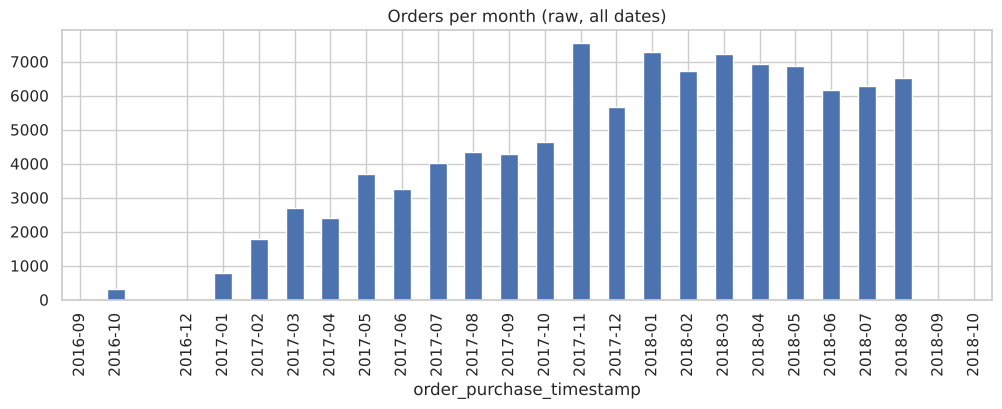

In [3]:
orders = tables["olist_orders_dataset"]
orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])
print(orders["order_status"].value_counts())
monthly = orders.groupby(orders["order_purchase_timestamp"].dt.to_period("M")).size()
monthly.plot(kind="bar", figsize=(12, 3.5), title="Orders per month (raw, all dates)");

**Decision:** keep January 2017 to August 2018. Late 2016 has almost no orders and September to October 2018 is cut off, which would distort any trend.

## Missing values and duplicates

In [4]:
checks = []
for name, df in tables.items():
    checks.append({"table": name, "rows": len(df), "duplicate_rows": int(df.duplicated().sum()), "columns_with_nulls": int((df.isna().sum() > 0).sum())})
pd.DataFrame(checks)

,table,rows,duplicate_rows,columns_with_nulls
0,olist_orders_dataset,99441,0,3
1,olist_order_items_dataset,112650,0,0
2,olist_customers_dataset,99441,0,0
3,olist_order_payments_dataset,103886,0,0
4,olist_order_reviews_dataset,100000,0,2
5,olist_products_dataset,32951,0,8
6,olist_sellers_dataset,3095,0,0
7,product_category_name_translation,71,0,0


In [5]:
reviews = tables["olist_order_reviews_dataset"]
print("orders with more than one review:", int((reviews.groupby("order_id").size() > 1).sum()))
cust = tables["olist_customers_dataset"]
print("customer_id rows:", len(cust), "| real unique customers (customer_unique_id):", cust["customer_unique_id"].nunique())

orders with more than one review: 555
customer_id rows: 99441 | real unique customers (customer_unique_id): 96096


**Key finding:** `customer_id` is created per order, so counting it would treat every order as a new customer. All customer analysis uses `customer_unique_id`. For orders with several reviews, the most recent review is kept.

## Prepared tables
`scripts/prepare_data.py` builds one row per order and one row per item, translates category names to English, and adds delivery days, late flag and review score.

In [6]:
prepared = pd.read_csv(ROOT / "data" / "processed" / "orders.csv")
print(prepared.shape)
prepared[["order_id", "order_month", "order_status", "item_revenue", "freight", "delivery_days", "is_late", "review_score", "payment_type"]].head()

(99092, 23)


,order_id,order_month,order_status,item_revenue,freight,delivery_days,is_late,review_score,payment_type
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10,delivered,29.99,8.72,8.44,False,4,voucher
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07,delivered,118.70,22.76,13.78,False,4,boleto
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08,delivered,159.90,19.22,9.39,False,5,credit_card
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11,delivered,45.00,27.20,13.21,False,5,credit_card
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02,delivered,19.90,8.72,2.87,False,5,credit_card
